### Reservoir Facies Classification using Random Forest

#### Dataset Exploration

In [57]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [58]:
df = pd.read_csv('facies_vectors.csv')

In [59]:
df.head(5)

,Facies,Formation,Well Name,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
0,3,A1 SH,SHRIMPLIN,2793.0,77.45,0.664,9.9,11.915,4.6,1,1.000
1,3,A1 SH,SHRIMPLIN,2793.5,78.26,0.661,14.2,12.565,4.1,1,0.979
2,3,A1 SH,SHRIMPLIN,2794.0,79.05,0.658,14.8,13.050,3.6,1,0.957
3,3,A1 SH,SHRIMPLIN,2794.5,86.10,0.655,13.9,13.115,3.5,1,0.936
4,3,A1 SH,SHRIMPLIN,2795.0,74.58,0.647,13.5,13.300,3.4,1,0.915


In [60]:
df['Well Name'] = df['Well Name'].astype('category')
df['Formation'] = df['Formation'].astype('category')

unique_wells = df['Well Name'].unique()
print("Unique Wells in Dataset:")
print(unique_wells)

Unique Wells in Dataset:
['SHRIMPLIN', 'ALEXANDER D', 'SHANKLE', 'LUKE G U', 'KIMZEY A', 'CROSS H CATTLE', 'NOLAN', 'Recruit F9', 'NEWBY', 'CHURCHMAN BIBLE']
Categories (10, str): ['ALEXANDER D', 'CHURCHMAN BIBLE', 'CROSS H CATTLE', 'KIMZEY A', ..., 'NOLAN', 'Recruit F9', 'SHANKLE', 'SHRIMPLIN']


In [61]:
# 1=sandstone, 2=c_siltstone, 3=f_siltstone, 4=marine_silt_shale, 
# 5=mudstone, 6=wackestone, 7=dolomite, 8=packstone, 9=bafflestone

facies_colors = ['#F4D03F', '#F5B041','#DC7633','#6E2C00',
                 '#1B4F72','#2E86C1', '#AED6F1', '#A569BD', '#196F3D']

facies_labels = ['SS', 'CSiS', 'FSiS', 'SiSh', 'MS',
                 'WS', 'D','PS', 'BS']

# Create a dictionary mapping facies labels to their respective colors
facies_color_map = {}
for ind, label in enumerate(facies_labels):
    facies_color_map[label] = facies_colors[ind]

# Function to map the integer to the string label
def label_facies(row, labels):
    # We subtract 1 because Python lists are 0-indexed, but Facies start at 1
    return labels[row['Facies'] - 1]

# Apply the function to create a new column
df.loc[:, 'FaciesLabels'] = df.apply(lambda row: label_facies(row, facies_labels), axis=1)

# Display the statistical summary of the dataset
display(df.describe())

,Facies,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
count,4149.000000,4149.000000,4149.000000,4149.000000,4149.000000,4149.000000,3232.000000,4149.000000,4149.000000
mean,4.503254,2906.867438,64.933985,0.659566,4.402484,13.201066,3.725014,1.518438,0.521852
std,2.474324,133.300164,30.302530,0.252703,5.274947,7.132846,0.896152,0.499720,0.286644
min,1.000000,2573.500000,10.149000,-0.025949,-21.832000,0.550000,0.200000,1.000000,0.000000
25%,2.000000,2821.500000,44.730000,0.498000,1.600000,8.500000,3.100000,1.000000,0.277000
50%,4.000000,2932.500000,64.990000,0.639000,4.300000,12.020000,3.551500,2.000000,0.528000
75%,6.000000,3007.000000,79.438000,0.822000,7.500000,16.050000,4.300000,2.000000,0.769000
max,9.000000,3138.000000,361.150000,1.800000,19.312000,84.400000,8.094000,2.000000,1.000000


In [62]:
PE_mask = df['PE'].notnull().values
df = df[PE_mask]
print(f"Total rows after removing missing PE values: {len(df)}")

Total rows after removing missing PE values: 3232


In [63]:
def make_facies_log_plot(logs, facies_colors):
    #make sure logs are sorted by depth
    logs = logs.sort_values(by='Depth')
    cmap_facies = colors.ListedColormap(
            facies_colors[0:len(facies_colors)], 'indexed')
    
    ztop=logs.Depth.min(); zbot=logs.Depth.max()
    
    cluster=np.repeat(np.expand_dims(logs['Facies'].values,1), 100, 1)
    
    f, ax = plt.subplots(nrows=1, ncols=6, figsize=(8, 12))
    ax[0].plot(logs.GR, logs.Depth, '-g')
    ax[1].plot(logs.ILD_log10, logs.Depth, '-')
    ax[2].plot(logs.DeltaPHI, logs.Depth, '-', color='0.5')
    ax[3].plot(logs.PHIND, logs.Depth, '-', color='r')
    ax[4].plot(logs.PE, logs.Depth, '-', color='black')
    im=ax[5].imshow(cluster, interpolation='none', aspect='auto',
                    cmap=cmap_facies,vmin=1,vmax=9)
    
    divider = make_axes_locatable(ax[5])
    cax = divider.append_axes("right", size="20%", pad=0.05)
    cbar=plt.colorbar(im, cax=cax)
    cbar.set_label((17*' ').join([' SS ', 'CSiS', 'FSiS', 
                                'SiSh', ' MS ', ' WS ', ' D  ', 
                                ' PS ', ' BS ']))
    cbar.set_ticks(range(0,1)); cbar.set_ticklabels('')
    
    for i in range(len(ax)-1):
        ax[i].set_ylim(ztop,zbot)
        ax[i].invert_yaxis()
        ax[i].grid(True, linestyle='--', alpha=0.7) # explicitly set it to True! (added styling for a cleaner look)
        ax[i].locator_params(axis='x', nbins=3)
        ax[i].tick_params(axis='both', labelsize=8) 
        
    ax[5].tick_params(axis='both', labelsize=8) 

    ax[0].set_xlabel("GR")
    ax[0].set_xlim(logs.GR.min(),logs.GR.max())
    ax[1].set_xlabel("ILD_log10")
    ax[1].set_xlim(logs.ILD_log10.min(),logs.ILD_log10.max())
    ax[2].set_xlabel("DeltaPHI")
    ax[2].set_xlim(logs.DeltaPHI.min(),logs.DeltaPHI.max())
    ax[3].set_xlabel("PHIND")
    ax[3].set_xlim(logs.PHIND.min(),logs.PHIND.max())
    ax[4].set_xlabel("PE")
    ax[4].set_xlim(logs.PE.min(),logs.PE.max())
    ax[5].set_xlabel('Facies')
    
    ax[1].set_yticklabels([]); ax[2].set_yticklabels([]); ax[3].set_yticklabels([])
    ax[4].set_yticklabels([]); ax[5].set_yticklabels([])
    ax[5].set_xticklabels([])
    f.suptitle('Well: %s'%logs.iloc[0]['Well Name'], fontsize=14,y=0.94)

Visualizing well: CHRUCHMAN BIBLE
Visualizing well: LUKE G U


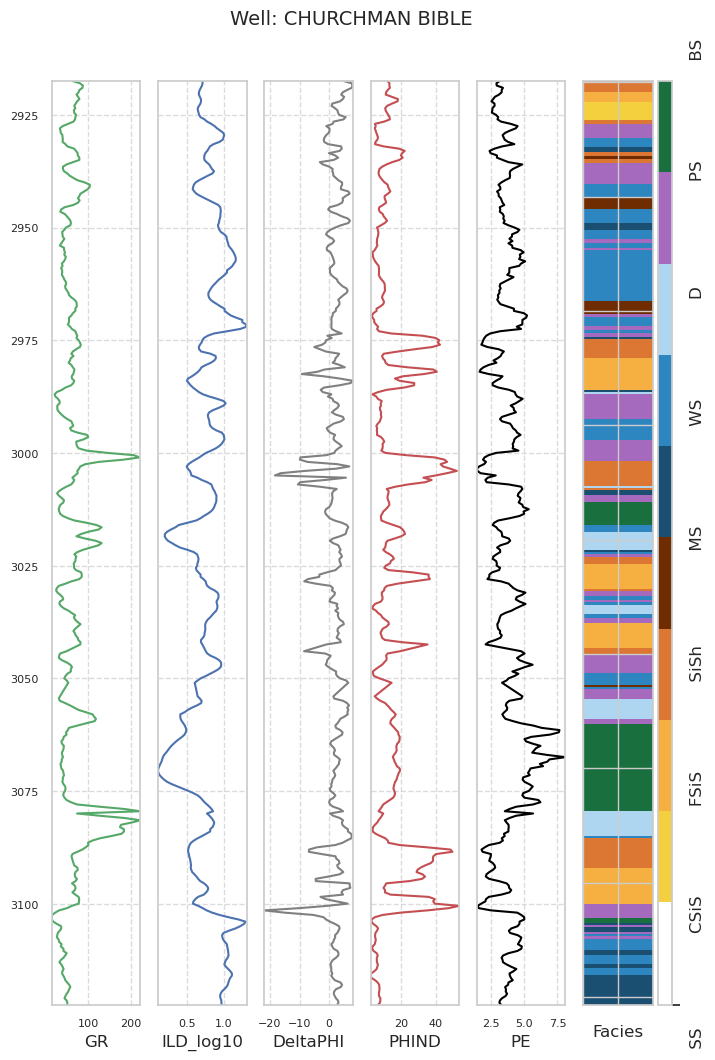

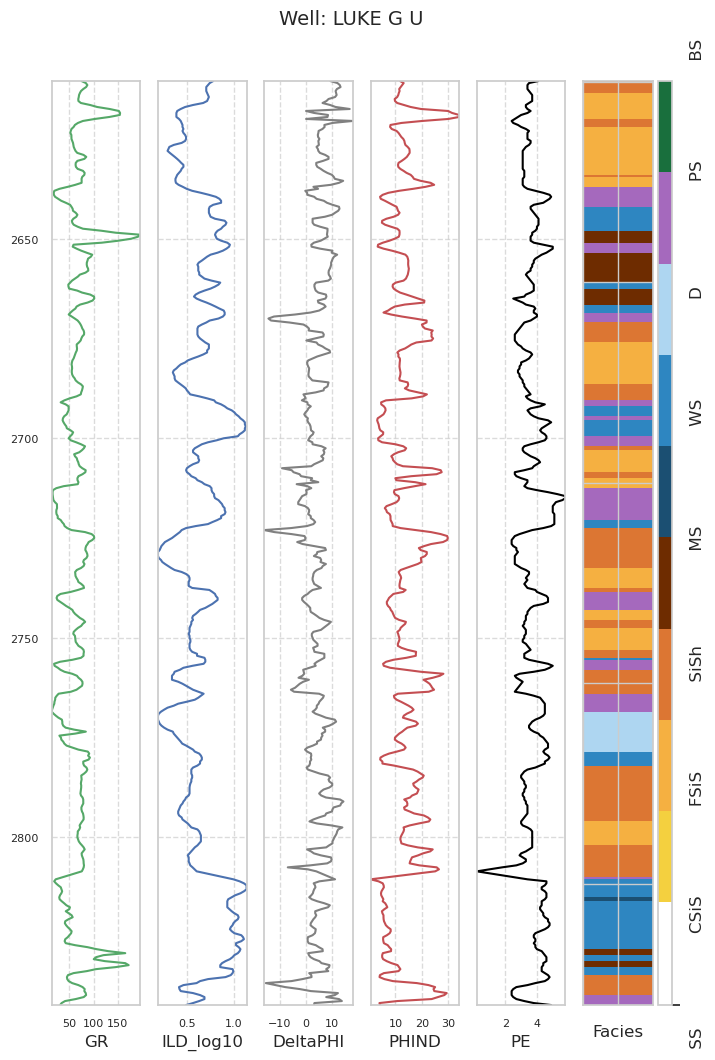

In [64]:
# Plotting the CHURCHMAN BIBLE well
print("Visualizing well: CHRUCHMAN BIBLE")
make_facies_log_plot(
    df[df['Well Name'] == 'CHURCHMAN BIBLE'],
    facies_colors
)

# Plotting the ALEXANDER D well
print("Visualizing well: LUKE G U")
make_facies_log_plot(
    df[df['Well Name'] == 'LUKE G U'],
    facies_colors
)

In [65]:
# See which wells survived the PE filter
available_wells = df['Well Name'].unique()
print("Wells available for plotting:")
print(available_wells)

Wells available for plotting:
['SHRIMPLIN', 'SHANKLE', 'LUKE G U', 'CROSS H CATTLE', 'NOLAN', 'Recruit F9', 'NEWBY', 'CHURCHMAN BIBLE']
Categories (10, str): ['ALEXANDER D', 'CHURCHMAN BIBLE', 'CROSS H CATTLE', 'KIMZEY A', ..., 'NOLAN', 'Recruit F9', 'SHANKLE', 'SHRIMPLIN']


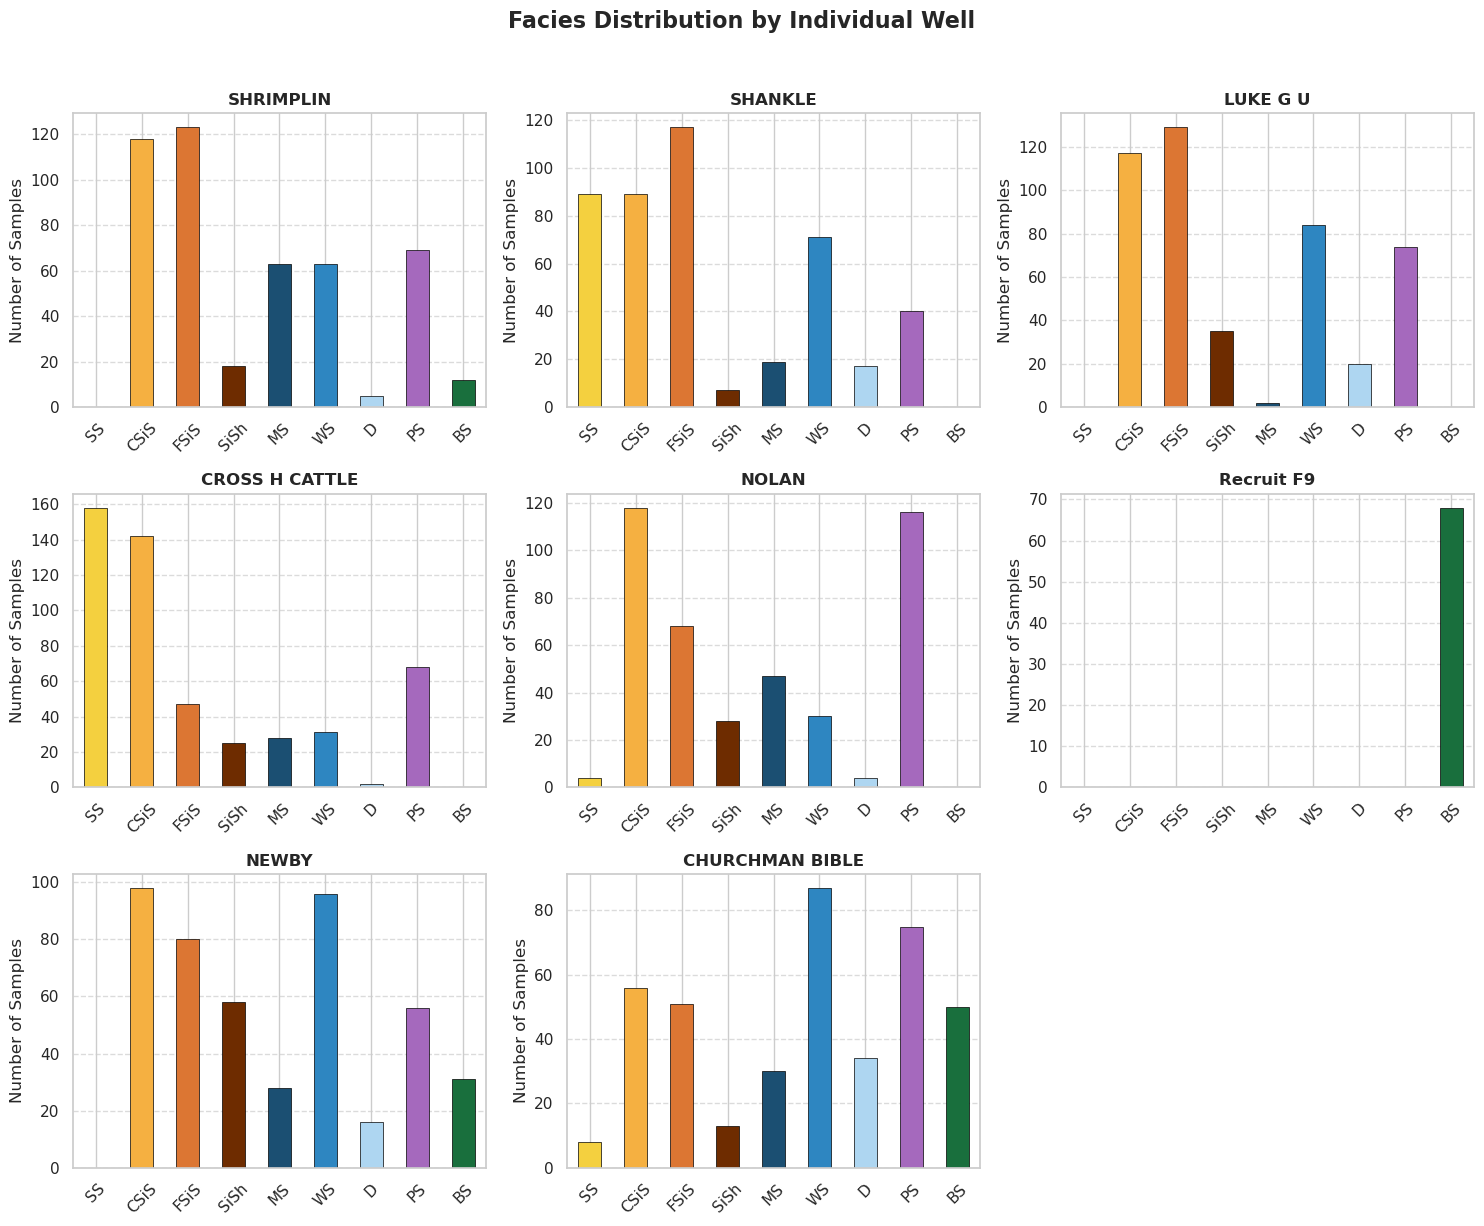

In [68]:
import math

wells = df['Well Name'].unique()
num_wells = len(wells)

# 2. Determine grid size (let's do 3 columns, and however many rows we need)
cols = 3
rows = math.ceil(num_wells / cols)

# 3. Create the figure and axes grid
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(15, 4 * rows))
axes = axes.flatten() # Flatten the 2D array of axes for easy looping

# 4. Loop through each well and plot its data on a specific axis
for i, well in enumerate(wells):
    ax = axes[i]
    
    # Isolate data for this specific well
    well_data = df[df['Well Name'] == well]
    
    # Count the facies and sort by facies number
    counts = well_data['Facies'].value_counts().sort_index()
    
    # Crucial step: Reindex to ensure all 9 facies are on the x-axis, 
    # even if this specific well has 0 samples of a certain rock type.
    counts = counts.reindex(range(1, 10), fill_value=0)
    counts.index = facies_labels
    
    # Plot the bar chart
    counts.plot(kind='bar', color=facies_colors, ax=ax, edgecolor='black', linewidth=0.5)
    
    # Formatting
    ax.set_title(well, fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Samples')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.tick_params(axis='x', rotation=45)

# 5. Hide any extra, empty subplots if the number of wells doesn't perfectly fill the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 6. Add a main title and render
fig.suptitle('Facies Distribution by Individual Well', fontsize=16, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

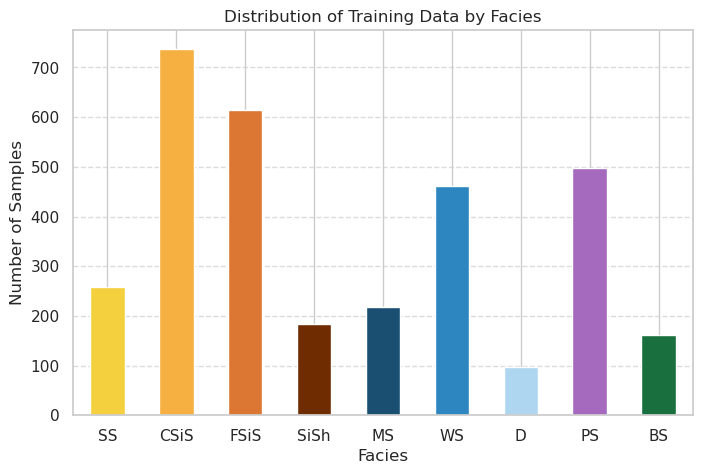

Exact Sample Counts:
SS      259
CSiS    738
FSiS    615
SiSh    184
MS      217
WS      462
D        98
PS      498
BS      161
Name: count, dtype: int64


In [67]:
# 1. Count the number of unique entries for each facies, sort them by facies number
facies_counts = df['Facies'].value_counts().sort_index()

# 2. Use facies labels (defined earlier) to index each count for a readable x-axis
facies_counts.index = facies_labels

# 3. Create the bar plot
facies_counts.plot(
    kind='bar', 
    color=facies_colors, 
    title='Distribution of Training Data by Facies',
    figsize=(8, 5) # Optional: Makes the plot slightly wider so labels don't crowd
)

# 4. Add formatting and render
plt.xlabel('Facies')
plt.ylabel('Number of Samples')
plt.grid(axis='y', linestyle='--', alpha=0.7) # Adds faint horizontal lines for readability
plt.xticks(rotation=0) # Keeps the facies labels upright
plt.show()

# 5. Print the raw numbers below the chart
print("Exact Sample Counts:")
print(facies_counts)

#### Conditioning the Dataset

In [69]:
correct_facies_labels = df['Facies'].values

feature_vectors = df.drop(['Formation', 'Well Name', 'Depth','Facies','FaciesLabels'], axis=1)
feature_vectors.describe()

,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
count,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000
mean,66.135769,0.642719,3.559642,13.483213,3.725014,1.498453,0.520287
std,30.854826,0.241845,5.228948,7.698980,0.896152,0.500075,0.286792
min,13.250000,-0.025949,-21.832000,0.550000,0.200000,1.000000,0.010000
25%,46.918750,0.492750,1.163750,8.346750,3.100000,1.000000,0.273000
50%,65.721500,0.624437,3.500000,12.150000,3.551500,1.000000,0.526000
75%,79.626250,0.812735,6.432500,16.453750,4.300000,2.000000,0.767250
max,361.150000,1.480000,18.600000,84.400000,8.094000,2.000000,1.000000


In [70]:
from sklearn import preprocessing

scaler = preprocessing.StandardScaler().fit(feature_vectors)
scaled_features = scaler.transform(feature_vectors)

In [74]:
import sklearn
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
        scaled_features, correct_facies_labels, test_size=0.2, random_state=42)

print(f"\nTraining features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")


Training features shape: (2585, 7)
Testing features shape: (647, 7)


In [75]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# 1. Initialize the Random Forest
# We use class_weight='balanced' to handle the massive imbalance we saw in the EDA phase
# n_estimators=100 means we are building 100 decision trees
clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# 2. Train the model
clf.fit(X_train, y_train)

# 3. Predict on the unseen test data
predicted_labels = clf.predict(X_test)

In [78]:
import numpy as np

# Exact accuracy definition
def accuracy(conf):
    total_correct = 0.
    nb_classes = conf.shape[0]
    for i in np.arange(0,nb_classes):
        total_correct += conf[i][i]
    acc = total_correct/sum(sum(conf))
    return acc

# Adjacent facies definition and accuracy
adjacent_facies = np.array([[1], [0,2], [1], [4], [3,5], [4,6,7], [5,7], [5,6,8], [6,7]], dtype=object)

def accuracy_adjacent(conf, adjacent_facies):
    nb_classes = conf.shape[0]
    total_correct = 0.
    for i in np.arange(0,nb_classes):
        total_correct += conf[i][i]
        for j in adjacent_facies[i]:
            total_correct += conf[i][j]
    return total_correct / sum(sum(conf))

# Print the results
print('Random Forest Facies classification accuracy = %f' % accuracy(conf))
print('Random Forest Adjacent facies classification accuracy = %f' % accuracy_adjacent(conf, adjacent_facies))

Random Forest Facies classification accuracy = 0.732612
Random Forest Adjacent facies classification accuracy = 0.930448


#### Applying the classification model to new data

In [80]:
well_data = pd.read_csv('validation_data_nofacies.csv')
well_data['Well Name'] = well_data['Well Name'].astype('category')
well_data['Formation'] = well_data['Formation'].astype('category')
well_features = well_data.drop(['Formation', 'Well Name', 'Depth'], axis=1)

In [81]:
X_unknown = scaler.transform(well_features)

In [83]:
y_unknown = clf.predict(X_unknown)
well_data['Facies'] = y_unknown

# Display the unique wells to confirm successful processing
print("Wells successfully classified:", well_data['Well Name'].unique())

Wells successfully classified: ['STUART', 'CRAWFORD']
Categories (2, str): ['CRAWFORD', 'STUART']



--- Visualizing Predicted Facies for STUART ---


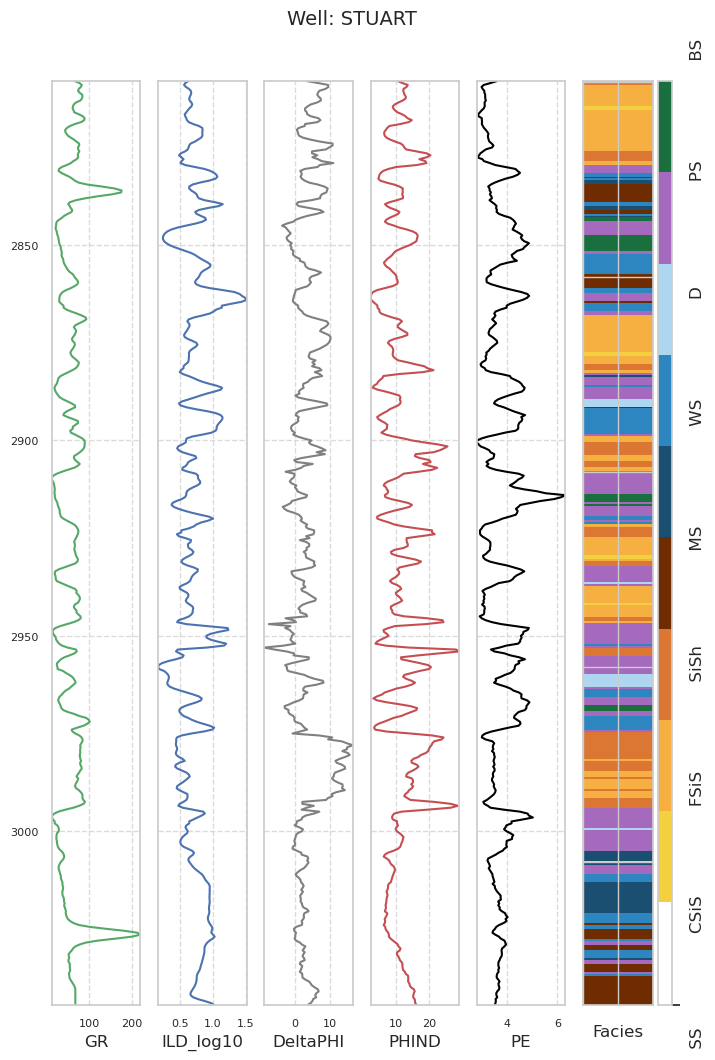


--- Visualizing Predicted Facies for CRAWFORD ---


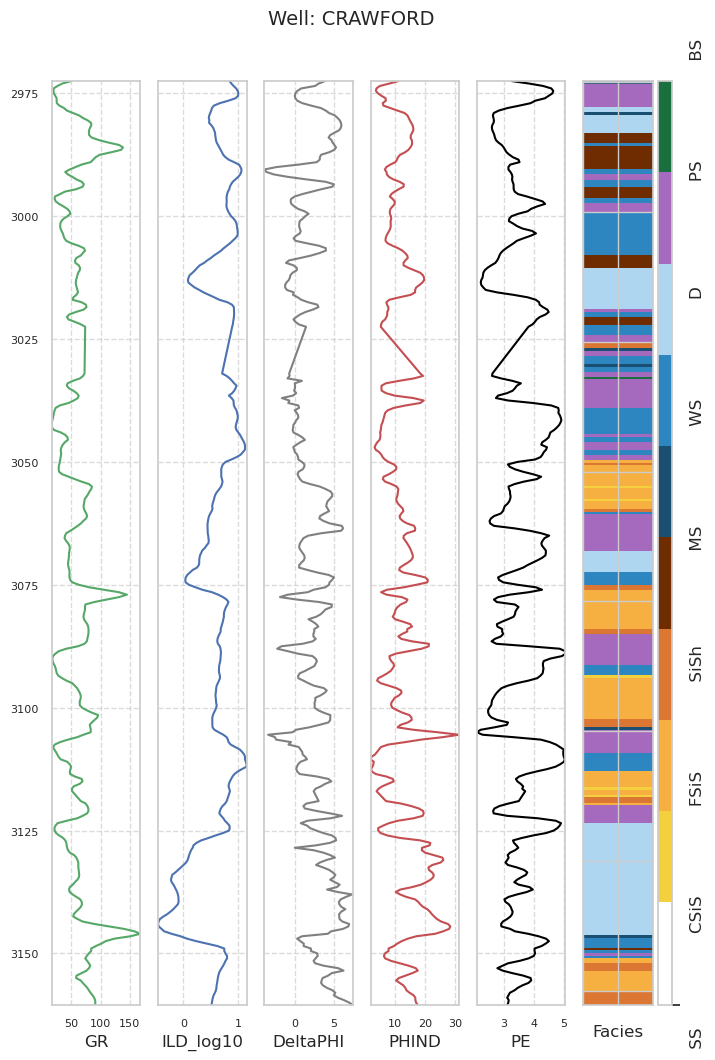

In [85]:
# 7. Plot the newly classified STUART well
print("\n--- Visualizing Predicted Facies for STUART ---")
make_facies_log_plot(
    well_data[well_data['Well Name'] == 'STUART'],
    facies_colors
)
plt.show()

# 8. Plot the newly classified CRAWFORD well
print("\n--- Visualizing Predicted Facies for CRAWFORD ---")
make_facies_log_plot(
    well_data[well_data['Well Name'] == 'CRAWFORD'],
    facies_colors
)
plt.show()